<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/08-visualization/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: A Visual Report on a Penguin Classifier

Training a model is half the job. The other half is understanding what it learned and explaining it to people who won't read your code. Charts do both.

In this project you'll train classifiers on the penguin data and build a set of **diagnostic charts**, the ones you'd actually make in a real project:

1. **The data**: can the features separate the species at all?
2. **Decision regions**: how does each model divide up the feature space, and what does overfitting look like?
3. **A complexity curve**: choosing k for k-NN with a validation set
4. **A learning curve**: is the model still learning, or overfitting?
5. **A confusion matrix**: which species get confused?
6. **Confidence**: is the model more sure when it's right than when it's wrong?

Then you'll assemble them into a single **one-page report**, saved as an image and a Markdown file, with titles that state each finding.

The models are written in NumPy, as in Module 6, so the focus stays on the charts.

## Setup

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter

plain = FuncFormatter(lambda value, _: f"{value:g}")     # 0.1 instead of 10^-1 on log axes
LOSS_TICKS = [0.03, 0.05, 0.1, 0.2, 0.4, 0.7]


def plain_log_axis(ax, ticks):
    """Log-scale y axis with a few readable tick labels instead of powers of ten."""
    ax.set_yscale("log")
    ax.set_yticks(ticks)
    ax.yaxis.set_major_formatter(plain)
    ax.yaxis.set_minor_formatter(NullFormatter())

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COLOURS = dict(zip(SPECIES, PALETTE))
MARKERS = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}

penguins = pd.read_csv(local if local.exists() else DATA_URL).dropna(subset=FEATURES)
penguins["label"] = penguins["species"].map({s: i for i, s in enumerate(SPECIES)})

# stratified 60 / 20 / 20 split into train, validation and test
test = penguins.groupby("species").sample(frac=0.2, random_state=0)
rest = penguins.drop(index=test.index)
val = rest.groupby("species").sample(frac=0.25, random_state=0)
train = rest.drop(index=val.index)
print(f"train {len(train)}, validation {len(val)}, test {len(test)}")

train 205, validation 68, test 69


Three sets, as in Module 6: **train** to fit the models, **validation** to make choices (like k), and **test** used once at the end. Every chart below says which set it uses.

## Step 1: Can the features separate the species?

Before training anything, look at the data. We'll use two features at first, bill length and bill depth, because two features can be drawn directly, and Module 8's lesson showed these two hide an interesting story.

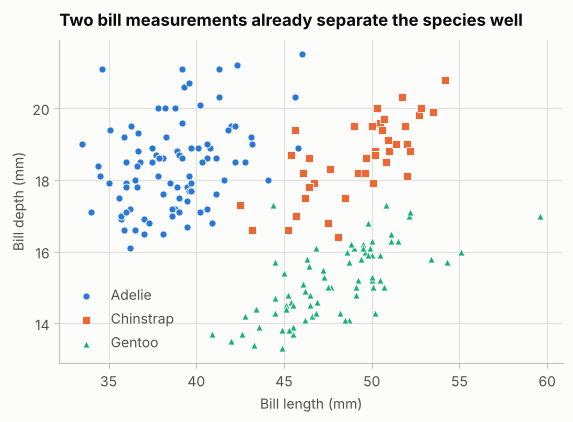

In [3]:
def scatter_species(ax, data, x, y, s=26):
    for sp in SPECIES:
        rows = data[data["species"] == sp]
        ax.scatter(rows[x], rows[y], color=COLOURS[sp], marker=MARKERS[sp], s=s,
                   edgecolors=SURFACE, linewidths=0.6, label=sp)


fig, ax = plt.subplots(figsize=(6.5, 4.2))
scatter_species(ax, train, "bill_length_mm", "bill_depth_mm")
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.set_title("Two bill measurements already separate the species well")
ax.legend(loc="lower left")
plt.show()

Three clusters with only a little overlap, mostly between Adelie and Chinstrap. A good classifier should be able to draw boundaries between them. That's what we'll look at next.

## Step 2: Two kinds of model

We need models that can be asked for a prediction at any point, so we can draw their decision regions. Two, each a few lines of NumPy:

- **k-nearest neighbours**, from Modules 1 and 6
- **softmax regression** (multi-class logistic regression), from Module 6

Both work on standardized features, using statistics from the training set only.

In [4]:
def standardizer(X_train):
    mean, std = X_train.mean(axis=0), X_train.std(axis=0)
    return lambda X: (X - mean) / std


def knn_model(X_train, y_train, k):
    def predict_proba(X):
        sq = (X ** 2).sum(1)[:, None] - 2 * X @ X_train.T + (X_train ** 2).sum(1)[None, :]
        nearest = np.argpartition(np.maximum(sq, 0), k - 1, axis=1)[:, :k] if k < len(X_train) else np.tile(np.arange(len(X_train)), (len(X), 1))
        votes = np.zeros((len(X), 3))
        np.add.at(votes, (np.arange(len(X))[:, None], y_train[nearest]), 1)
        return votes / k
    return predict_proba


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def softmax_regression(X_train, y_train, X_val, y_val, lr=0.5, epochs=300, l2=1e-3):
    n, d = X_train.shape
    W, b = np.zeros((d, 3)), np.zeros(3)
    Y = np.eye(3)[y_train]
    history = []
    for epoch in range(1, epochs + 1):
        P = softmax(X_train @ W + b)
        W -= lr * (X_train.T @ (P - Y) / n + l2 * W)
        b -= lr * (P - Y).mean(axis=0)
        if epoch % 5 == 0 or epoch == 1:
            def loss(X, y):
                p = softmax(X @ W + b)
                return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())
            history.append({"epoch": epoch, "train_loss": loss(X_train, y_train), "val_loss": loss(X_val, y_val)})
    weights = (W.copy(), b.copy())
    return (lambda X: softmax(X @ weights[0] + weights[1])), pd.DataFrame(history)

Both return a `predict_proba` function: give it points, and it returns a probability for each species. For k-NN, the "probability" is just the share of the `k` neighbours that voted for each species.

`softmax_regression` also returns its training history, every 5 epochs, for the learning curve later.

## Step 3: Decision regions, and what overfitting looks like

Now the most revealing chart in this project. For each model, we predict a species at every point of a fine grid and colour the regions. This is the `decision_regions` exercise, extended to several models side by side.

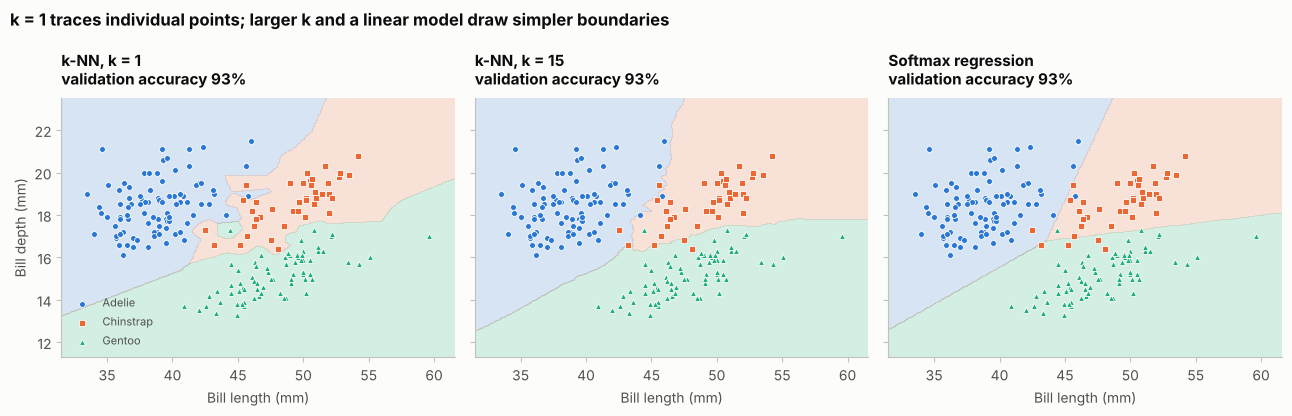

In [5]:
two = ["bill_length_mm", "bill_depth_mm"]
scale2 = standardizer(train[two].to_numpy())
X2_train, y_train = scale2(train[two].to_numpy()), train["label"].to_numpy()
X2_val, y_val = scale2(val[two].to_numpy()), val["label"].to_numpy()

models_2d = {
    "k-NN, k = 1": knn_model(X2_train, y_train, 1),
    "k-NN, k = 15": knn_model(X2_train, y_train, 15),
    "Softmax regression": softmax_regression(X2_train, y_train, X2_val, y_val)[0],
}

lo = train[two].min().to_numpy() - 2
hi = train[two].max().to_numpy() + 2
gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
grid = np.column_stack([gx.ravel(), gy.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, (name, predict_proba) in zip(axes, models_2d.items()):
    regions = predict_proba(scale2(grid)).argmax(axis=1).reshape(gx.shape)
    ax.contourf(gx, gy, regions, levels=[-0.5, 0.5, 1.5, 2.5], cmap=ListedColormap(PALETTE[:3]), alpha=0.18)
    scatter_species(ax, train, *two, s=18)
    val_acc = (predict_proba(X2_val).argmax(axis=1) == y_val).mean()
    ax.set_title(f"{name}\nvalidation accuracy {val_acc:.0%}", fontsize=11)
    ax.grid(False)
    ax.set_xlabel("Bill length (mm)")
axes[0].set_ylabel("Bill depth (mm)")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("k = 1 traces individual points; larger k and a linear model draw simpler boundaries",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Compare the three:

- **k = 1** carves out little islands around individual training points. Wherever one Chinstrap sits among Adelies, it gets its own small region. That's **overfitting** made visible: the model memorises the training data, including its accidents.
- **k = 15** averages over more neighbours, so the boundaries are smoother and the islands disappear.
- **Softmax regression** can only draw straight boundaries. Here that's enough, because the clusters are roughly separated by straight lines.

Look at the titles: **all three score exactly the same on the validation set**. Accuracy alone would call them equivalent, yet they behave very differently in the gaps between training points, which is exactly where new data often lands. Only the picture shows that.

`fig.suptitle` with `x=0.01, ha="left"` puts the overall title at the left, lined up with the panel titles.

## Step 4: Choosing k with a complexity curve

How do we pick k? We try a range of values and measure accuracy on both the training and the validation sets, now using all four features:

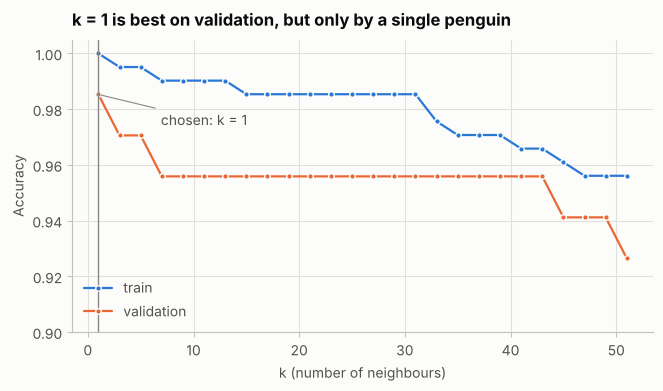

best k on validation: 1 (98.5%)


In [6]:
scale4 = standardizer(train[FEATURES].to_numpy())
X_train, X_val, X_test = (scale4(d[FEATURES].to_numpy()) for d in (train, val, test))
y_test = test["label"].to_numpy()

ks = list(range(1, 52, 2))
train_acc, val_acc = [], []
for k in ks:
    model = knn_model(X_train, y_train, k)
    train_acc.append((model(X_train).argmax(axis=1) == y_train).mean())
    val_acc.append((model(X_val).argmax(axis=1) == y_val).mean())

best_k = ks[int(np.argmax(val_acc))]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(ks, train_acc, color=PALETTE[0], marker="o", markersize=4, markeredgecolor=SURFACE, label="train")
ax.plot(ks, val_acc, color=PALETTE[1], marker="o", markersize=4, markeredgecolor=SURFACE, label="validation")
ax.axvline(best_k, color=MUTED, linewidth=1)
ax.annotate(f"chosen: k = {best_k}", xy=(best_k, max(val_acc)), xytext=(45, -22),
            textcoords="offset points", color=INK_2,
            arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8})
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.9, 1.005)
ax.set_title("k = 1 is best on validation, but only by a single penguin")
ax.legend(loc="lower left")
plt.show()
print("best k on validation:", best_k, f"({max(val_acc):.1%})")

At k = 1, training accuracy is 100%, since every training point is its own nearest neighbour, so that number means nothing. The validation curve is the one that matters, and it does peak at k = 1.

But look at the scale. 98.5% at k = 1 is 67 out of 68 validation penguins. k = 3 and k = 5 get 66, and almost everything up to k = 43 gets 65. **A single penguin decides it.** With all four measurements, the species barely overlap, so memorising the training data costs very little here. The overfitting we saw with two features in step 3 matters much less with four.

We follow the procedure and take the k with the best validation score. But the honest summary is "almost any k up to about 40 works equally well". When validation differences are this small, many practitioners deliberately pick a simpler, smoother model (a larger k), since it's less likely to be thrown off by one odd training point. Either choice is defensible, as long as you don't pretend the difference is meaningful.

Two notes on the chart itself:

- **The y-axis starts at 0.9, not 0.** That's fine for a line chart showing how accuracy *changes* with k, unlike a bar chart, and zooming in is what makes the differences visible. The axis labels make the range clear.
- **The label is offset with a thin leader line** (`arrowprops`) rather than placed on top of the data, so it doesn't cover the points it's describing.

## Step 5: The learning curve

For softmax regression, the question is different: did it train long enough? The learning curve from the exercises answers it:

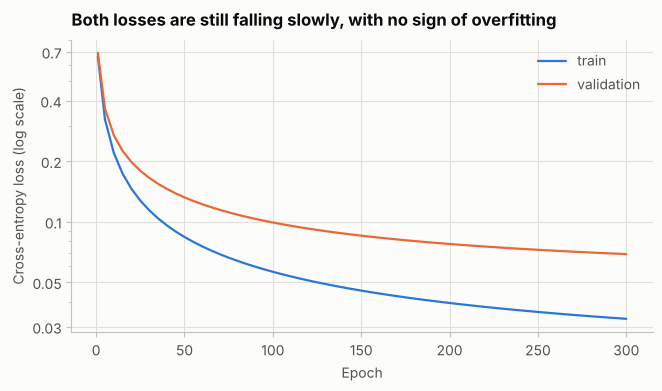

lowest validation loss 0.069 at epoch 300 of 300


In [7]:
softmax_proba, history = softmax_regression(X_train, y_train, X_val, y_val, lr=0.5, epochs=300)

best = history.loc[history["val_loss"].idxmin()]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(history["epoch"], history["train_loss"], color=PALETTE[0], label="train")
ax.plot(history["epoch"], history["val_loss"], color=PALETTE[1], label="validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss (log scale)")
plain_log_axis(ax, LOSS_TICKS)
ax.set_title("Both losses are still falling slowly, with no sign of overfitting")
ax.legend()
plt.show()
print(f"lowest validation loss {best['val_loss']:.3f} at epoch {int(best['epoch'])} of {int(history['epoch'].max())}")

Both curves drop steeply at first, then keep falling slowly, and the validation loss never turns back up: its lowest point is at the very last epoch. So there's no overfitting, and training for longer might help a little more. A linear model with four features and some regularization has little room to memorise noise.

The gap between the two curves is normal: a model always fits its own training data a bit better than new data. What would signal trouble is the validation curve *rising* while the training curve keeps falling, the pattern from the `learning_curves` exercise.

The y-axis is **logarithmic** (`ax.set_yscale("log")`). Losses often drop by a factor of 10 or more early on, and on a normal scale the interesting later part becomes a flat line squashed against the bottom. A log scale spreads it out. Whenever a quantity varies over several orders of magnitude, consider a log axis, and say so in the label, as here.

By default, Matplotlib labels log axes in scientific notation, like 6×10⁻¹, and labelling every in-between tick crowds the labels together. `plain_log_axis`, defined in the setup cell, picks a few round tick values, writes them as ordinary numbers like 0.6 with `f"{value:g}"`, and hides the labels of the in-between (minor) ticks.

## Step 6: The final evaluation

Both models are now chosen using the validation set. Time for the test set, once:

In [8]:
final_models = {
    f"k-NN (k = {best_k})": knn_model(X_train, y_train, best_k),
    "Softmax regression": softmax_proba,
}
test_results = {}
for name, predict_proba in final_models.items():
    proba = predict_proba(X_test)
    test_results[name] = proba
    print(f"{name:20s} test accuracy {(proba.argmax(axis=1) == y_test).mean():.1%}")

k-NN (k = 1)         test accuracy 97.1%
Softmax regression   test accuracy 98.6%


Both models do very well, as the decision regions suggested. For the report, we'll focus on softmax regression: it's as accurate, and it gives smoother probabilities than k-NN, whose "probabilities" can only be multiples of 1/k.

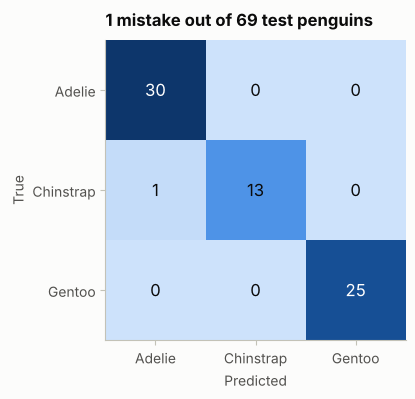

In [9]:
proba = test_results["Softmax regression"]
pred = proba.argmax(axis=1)
cm = np.bincount(y_test * 3 + pred, minlength=9).reshape(3, 3)

fig, ax = plt.subplots(figsize=(4.6, 3.9))
ax.imshow(cm, cmap=SEQUENTIAL)
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=12)
ax.set_xticks(range(3), SPECIES)
ax.set_yticks(range(3), SPECIES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.grid(False)
n_wrong = int(cm.sum() - np.trace(cm))
ax.set_title(f"{n_wrong} mistake{'s' if n_wrong != 1 else ''} out of {cm.sum()} test penguins")
plt.show()

## Step 7: Is the model more confident when it's right?

A good classifier should be *unsure* about the cases it gets wrong. If it's just as confident in its mistakes as in its correct answers, its probabilities can't be trusted to flag uncertain cases. Here's the model's confidence (its highest probability) for every test penguin, split by correct and wrong:

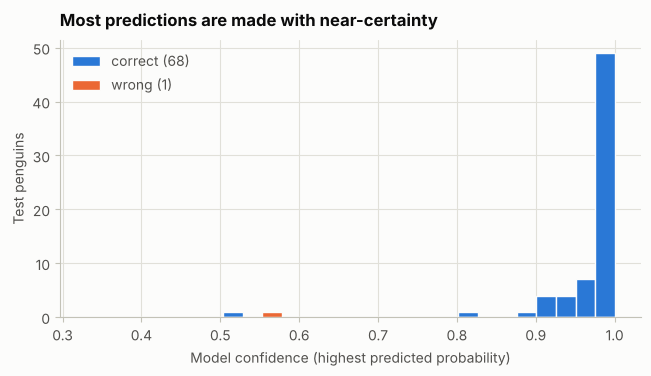

confidence of the mistakes: [0.567]
correct predictions with confidence below 0.9: 4


In [10]:
confidence = proba.max(axis=1)
correct = pred == y_test

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(0.33, 1.0, 28)
ax.hist(confidence[correct], bins=bins, color=PALETTE[0], edgecolor=SURFACE, linewidth=1,
        label=f"correct ({correct.sum()})")
ax.hist(confidence[~correct], bins=bins, color=PALETTE[1], edgecolor=SURFACE, linewidth=1,
        label=f"wrong ({(~correct).sum()})")
ax.set_xlabel("Model confidence (highest predicted probability)")
ax.set_ylabel("Test penguins")
ax.set_title("Most predictions are made with near-certainty")
ax.legend(loc="upper left")
plt.show()

if (~correct).any():
    print("confidence of the mistakes:", np.round(confidence[~correct], 3))
print(f"correct predictions with confidence below 0.9: {(confidence[correct] < 0.9).sum()}")

The vast majority of predictions sit at the far right, near 100% confidence, and they're right. The single mistake was made with only about 57% confidence, one of the least confident predictions on the whole test set. Unlike the Naive Bayes model in Module 5, which was confidently wrong, this model "knew" it was unsure. In practice, that's what lets you route uncertain cases to a person for checking.

Keep it in proportion, though: one mistake in a test set of 69 is an anecdote, not a measurement. Before trusting a model's probabilities in a real project, you'd check calibration on much more data (the second "Your turn" idea).

The two histograms use the same bin edges, so their bars line up, and the legend includes the counts, which matter here because one group is far smaller than the other.

## Step 8: The one-page report

Now we assemble the most important charts into one figure that someone could read in a minute. `GridSpec` lays out panels of different sizes in one figure:

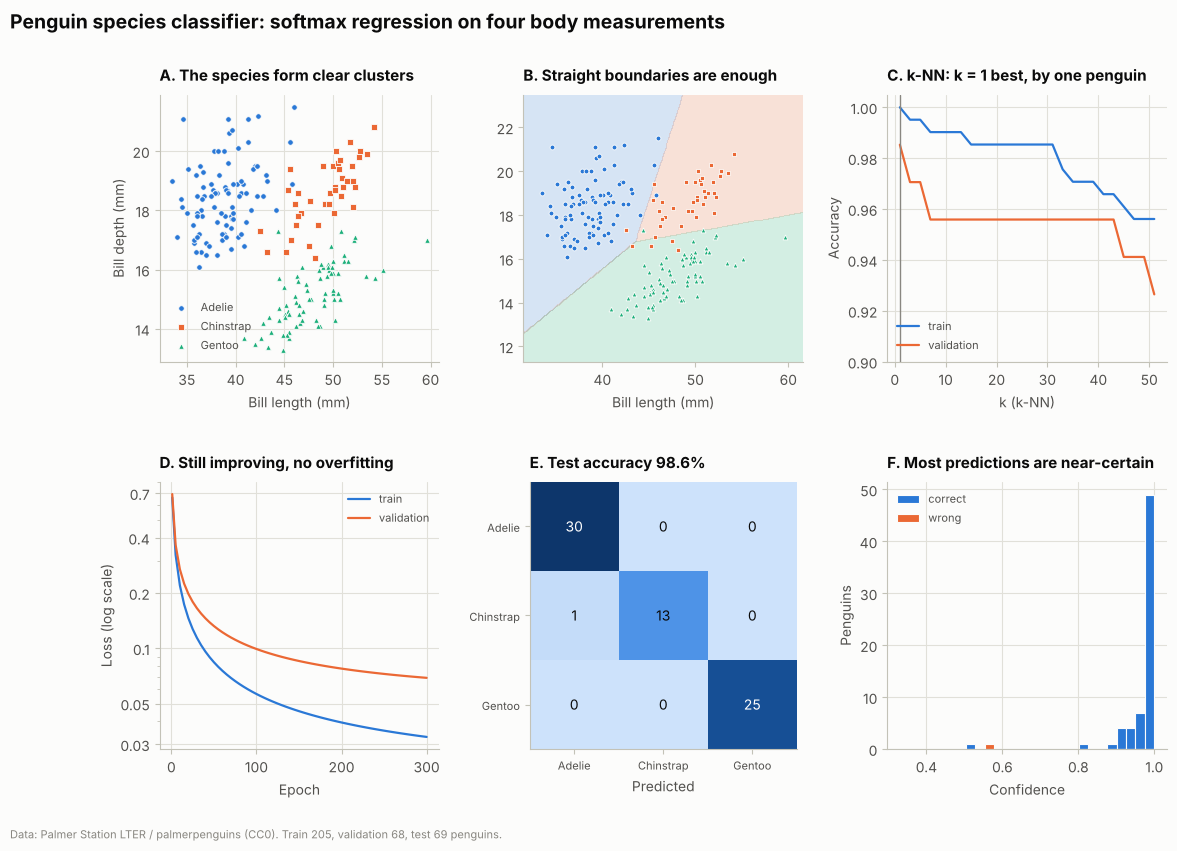

In [11]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(13, 8.5))
gs = GridSpec(2, 3, figure=fig, height_ratios=[1, 1], hspace=0.45, wspace=0.3)

# A: the data
ax = fig.add_subplot(gs[0, 0])
scatter_species(ax, train, *two, s=16)
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.set_title("A. The species form clear clusters", fontsize=11)
ax.legend(loc="lower left", fontsize=8)

# B: decision regions of the final model type, on two features
ax = fig.add_subplot(gs[0, 1])
regions = models_2d["Softmax regression"](scale2(grid)).argmax(axis=1).reshape(gx.shape)
ax.contourf(gx, gy, regions, levels=[-0.5, 0.5, 1.5, 2.5], cmap=ListedColormap(PALETTE[:3]), alpha=0.18)
scatter_species(ax, train, *two, s=12)
ax.set_xlabel("Bill length (mm)")
ax.grid(False)
ax.set_title("B. Straight boundaries are enough", fontsize=11)

# C: complexity curve
ax = fig.add_subplot(gs[0, 2])
ax.plot(ks, train_acc, color=PALETTE[0], label="train")
ax.plot(ks, val_acc, color=PALETTE[1], label="validation")
ax.axvline(best_k, color=MUTED, linewidth=1)
ax.set_ylim(0.9, 1.005)
ax.set_xlabel("k (k-NN)")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8, loc="lower left")
ax.set_title(f"C. k-NN: k = {best_k} best, by one penguin", fontsize=11)

# D: learning curve
ax = fig.add_subplot(gs[1, 0])
ax.plot(history["epoch"], history["train_loss"], color=PALETTE[0], label="train")
ax.plot(history["epoch"], history["val_loss"], color=PALETTE[1], label="validation")
plain_log_axis(ax, LOSS_TICKS)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (log scale)")
ax.legend(fontsize=8)
ax.set_title("D. Still improving, no overfitting", fontsize=11)

# E: confusion matrix
ax = fig.add_subplot(gs[1, 1])
ax.imshow(cm, cmap=SEQUENTIAL)
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else INK)
ax.set_xticks(range(3), SPECIES, fontsize=8)
ax.set_yticks(range(3), SPECIES, fontsize=8)
ax.set_xlabel("Predicted")
ax.grid(False)
test_acc = (pred == y_test).mean()
ax.set_title(f"E. Test accuracy {test_acc:.1%}", fontsize=11)

# F: confidence
ax = fig.add_subplot(gs[1, 2])
ax.hist(confidence[correct], bins=bins, color=PALETTE[0], edgecolor=SURFACE, linewidth=0.8, label="correct")
ax.hist(confidence[~correct], bins=bins, color=PALETTE[1], edgecolor=SURFACE, linewidth=0.8, label="wrong")
ax.set_xlabel("Confidence")
ax.set_ylabel("Penguins")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("F. Most predictions are near-certain", fontsize=11)

fig.suptitle("Penguin species classifier: softmax regression on four body measurements",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, f"Data: Palmer Station LTER / palmerpenguins (CC0). Train {len(train)}, "
         f"validation {len(val)}, test {len(test)} penguins.", color=MUTED, fontsize=8)

report_dir = Path("work") / "report"
report_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(report_dir / "penguin_model_report.png", bbox_inches="tight")
plt.show()
plt.close(fig)

Each panel title states its finding, so the page reads as a story from A to F even without the text: the data separates, a simple model is enough, here's how k was chosen, training behaved, here's the result, and the model is confident.

`GridSpec(2, 3)` divides the figure into a grid, and `gs[row, col]` picks a cell. Slices like `gs[0, 1:]` would let a panel span several cells, which is how you'd give an important chart more room.

Finally, a short written report to go with the image. A chart in a report should always come with a sentence or two of description, both to state the conclusion and as **alt text** for anyone using a screen reader:

In [12]:
report = f"""# Penguin species classifier

![Six-panel report: the three species form separate clusters in bill length and depth;
a linear model separates them with straight boundaries; k-NN validation accuracy peaks at k = {best_k},
though most values of k score within two penguins of it; softmax regression shows no overfitting; test accuracy {test_acc:.1%}
with {n_wrong} mistake(s); most predictions are made with near-certainty.](penguin_model_report.png)

## Summary

- **Model:** softmax regression on bill length, bill depth, flipper length and body mass, standardized.
- **Test accuracy:** {test_acc:.1%} on {len(test)} penguins never used for training or model choices.
- **Comparison:** k-NN with k = {best_k} (chosen on the validation set) scored
  {(test_results[f"k-NN (k = {best_k})"].argmax(axis=1) == y_test).mean():.1%} on the same test set.
- **Errors:** {n_wrong} of {len(test)}; Adelie and Chinstrap are the only pair that overlap in the data.

## Data

Palmer Penguins (Gorman, Williams and Fraser; Palmer Station LTER), CC0.
{len(penguins)} penguins with complete measurements; stratified 60 / 20 / 20 split, seed 0.
"""
(report_dir / "README.md").write_text(report, encoding="utf-8")
print(sorted(p.name for p in report_dir.iterdir()))

['README.md', 'penguin_model_report.png']


The alt text describes what the figure *shows* (the findings), not what it *looks like* ("a figure with six panels"). That's what someone who can't see the image needs. The numbers in the report are filled in from the actual results, so the text can never drift out of date with the figure.

## Your turn

1. **Bill length and flipper length.** Redraw the decision regions in step 3 using these two features instead. Do the species separate better or worse? Which pair of features would you choose if you could only use two?

2. **A calibration chart.** Group the test predictions into bins by confidence (0.4 to 0.5, 0.5 to 0.6, and so on) and plot the actual accuracy in each bin against the bin's average confidence. A perfectly calibrated model lies on the diagonal. It needs more data than this small test set to be meaningful, so try it on the digits model from Module 6.

3. **Per-species metrics.** Add a sorted horizontal bar chart of precision and recall per species. (Two measures per species: think about whether that's two charts, small multiples, or one chart with grouped bars and a legend.)

4. **Small multiples of features.** Draw a 2×2 grid of histograms, one per feature, each split by species, with each panel's title stating which species that feature separates best.

5. **Seaborn.** Rebuild panel A with `sns.scatterplot(..., hue="species", style="species", hue_order=SPECIES, palette=COLOURS)` and check that the colours and markers match ours exactly.

## What you used

- **Small multiples** with shared axes to compare models side by side
- **Decision regions** with `meshgrid`, one vectorized prediction call, and `contourf` with explicit class levels
- **Complexity and learning curves** with reference lines and annotations, and a **log scale** where values span orders of magnitude
- **A confusion matrix** heatmap with a sequential scale and readable cell labels
- **Overlaid histograms** with shared bins and counts in the legend
- **`GridSpec`** to compose a multi-panel report, and **`savefig`** with `bbox_inches="tight"`
- A consistent **house style**: one palette in a fixed order, markers as a second channel, titles that state findings, and a source note
- **Alt text** that describes findings, generated from the real numbers